### Hot tail generation Implementation

In [2]:
import sys
RE_path = './' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

In [3]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp

### DREAM implementation 

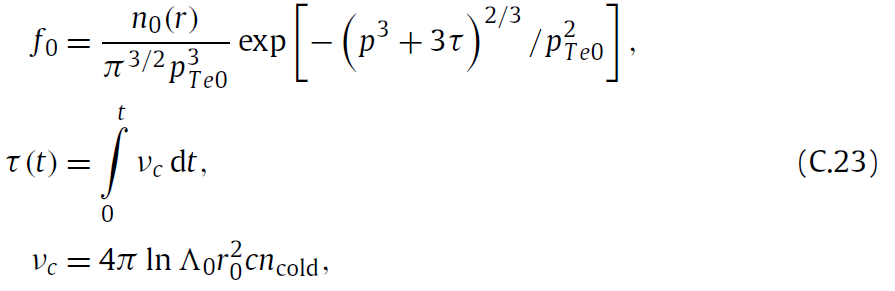

In [4]:
# n_0 is density
# p_Te0 is normalized momentum
# tau(t) is nu_c * t if we ignore nu_cold
# nu_c is function of columb log and radius
# let r = 1, use getColombLog(n_0, T)
# initialize p as a array for a distribution (p vs f_0)
# T0 is initial temperature (idk i need to convert i think)
m = const.m_e # kg
e = const.e # C 
c = const.c # m/s

def getf0(p, n_0, T0, t, n_cold):
    '''
    
    '''

    

    #T0 = T0 
    p_Te0 = np.sqrt(2*T0*e/(m*c**2)) 
    r0 = const.physical_constants["classical electron radius"][0]
    nu_c = 4*np.pi * getCoulombLog(n_0, T0) * r0**2*c*n_cold
    tau = nu_c * t

    expo = -((p**3 + 3*tau)**(2/3)) / (p_Te0**2)

    return n_0/(np.pi**1.5 * p_Te0**3) * np.exp(expo) 



0.01851549622873723
54.00881443555028
18.05387763949107


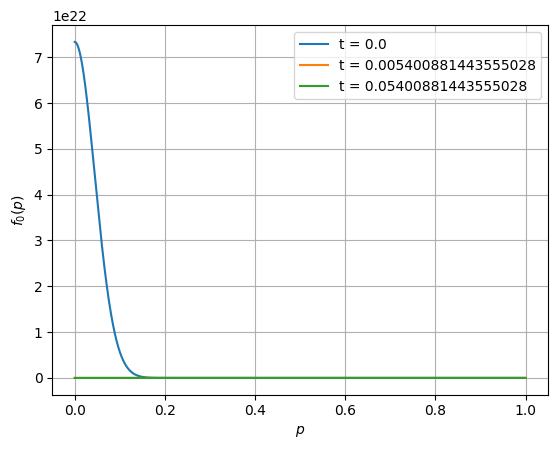

In [5]:
p  = np.linspace(0,1,10000)

n_0 = 1e20        # m^-3
n_cold = 1e20    # m^-3
T0 = 1e3           
r0 = const.physical_constants["classical electron radius"][0]
nu_c = 4*np.pi * getCoulombLog(n_0, T0) * r0**2*c*n_cold

print(1/nu_c)
print(nu_c)
print(getCoulombLog(n_0, T0))

t_list = [0, 10/nu_c, 20/nu_c, 40/nu_c, 80/nu_c]
t_list = np.array([0, 1e-4, 1e-3])

plt.figure()

for t in t_list:
    f0 = getf0(p, n_0, T0, t, n_cold)
    plt.plot(p, f0, label=rf"t = {t * nu_c}")

#plt.yscale("log")
plt.xlabel(r"$p$")
plt.ylabel(r"$f_0(p)$")
#plt.title("Eq. (C.23) distribution at $t=0$")
#plt.xlim()
plt.legend()
plt.grid(True)
plt.show()


0.021222163346995993
47.12054957118924
15.751292546497023


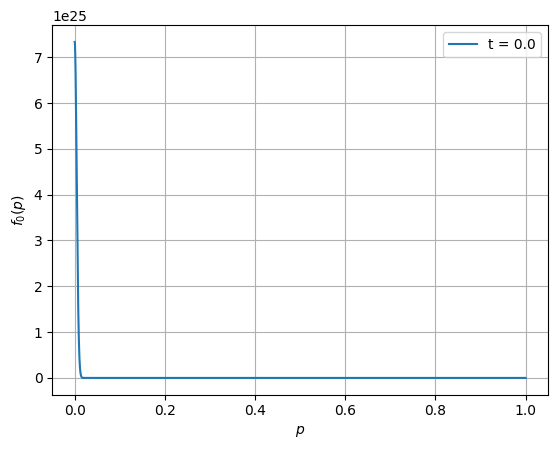

In [6]:
p  = np.linspace(0,1,10000)

n_0 = 1e20        # m^-3
n_cold = 1e20    # m^-3
T0 = 10           
r0 = const.physical_constants["classical electron radius"][0]
nu_c = 4*np.pi * getCoulombLog(n_0, T0) * r0**2*c*n_cold

print(1/nu_c)
print(nu_c)
print(getCoulombLog(n_0, T0))

t_list = [0]
#t_list = np.array([0, 1e-4, 1e-3])

plt.figure()

for t in t_list:
    f0 = getf0(p, n_0, T0, t, n_cold)
    plt.plot(p, f0, label=rf"t = {t * nu_c}")

#plt.yscale("log")
plt.xlabel(r"$p$")
plt.ylabel(r"$f_0(p)$")
#plt.title("Eq. (C.23) distribution at $t=0$")
#plt.xlim()
plt.legend()
plt.grid(True)
plt.show()


### Hot tail generation (Smith et al)
eq9: nneds temp evo from eq7, use eq16 for tau

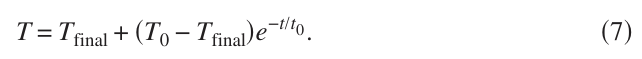
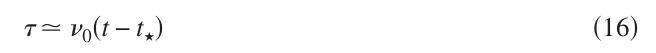

In [ ]:
m = const.m_e # kg
e = const.e # C 
c = const.c # m/s

def temperature(t, T0, Tf, t0):
    """
    Parameters:
    t: Time (s)
    T0: initial temp (eV)
    Tfinal: final temp (eV)
    t0: initial time (s)
    """
    #return Tf + (T0 - Tf) * np.exp(-t / t0)
    return Tf + (T0 - Tf) * np.exp(-t / t0)


def getvT0(T0):
    """
    T0: temp (eV)
    returns velocity in m/s
    """
   # return np.sqrt(2* const.k * T0 * e / m)
    return np.sqrt(2*T0*e/m)

def getnu0(n, T0):
    """
    T: temp (joules)
    vT: initial time (s)
    returns rate in s^-1
    """
    vT0 = getvT0(T0)
    lnL = 15 
    return n*e**4 * lnL/(4*np.pi * const.epsilon_0**2 * m**2 * vT0**3)

def getTau(nu0, t, t0):
    """
    t0: initial time (s)
    t: time (s)
    nu0: collision rate (s^-1)
    returns:
    tau (no unit) 
    """
    return nu0 * max(0.0, t - t0)




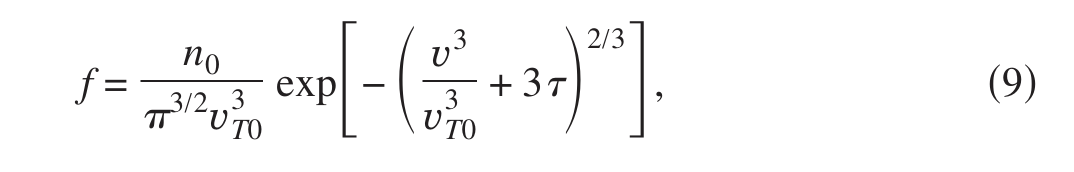

In [ ]:
def getf(v, n0, vT0, tau):
    """
    Corrected Maxwellian with tau
    v: velocity (m/s)
    n0: density (m^-3)
    vT0: initial thermal speed (m/s)
    tau: no units
    returns:
    f : m^3 
    """
    prefactor = n0 / (np.pi**1.5 * vT0**3)
    expo = -((v**3/vT0**3) + 3*tau)**(2/3)
    return prefactor * np.exp(expo)

'\ndef getMaxwellian(v, n0, vT0, tau):\n    prefactor = n0 / (np.pi**1.5 * vT0**3)\n    base = (v**3 / vT0**3) + 3*tau\n    expo = - np.maximum(base, 0.0) ** (2.0/3.0)\n    return prefactor * np.exp(expo)\n'

In [13]:
def getfm(v, n0, vT):
    """
    Basic one without tau
    v: velocity (m/s)
    n0: density (m^-3)
    vT: current thermal speed (m/s)
    returns:
    f : m^3 
    """
    prefactor = n0 / (np.pi**1.5 * vT**3)
    expo = -((v**2/vT**2))
    return prefactor * np.exp(expo)
    

### Recreating Figure 4

vT0: 33022241.068624627


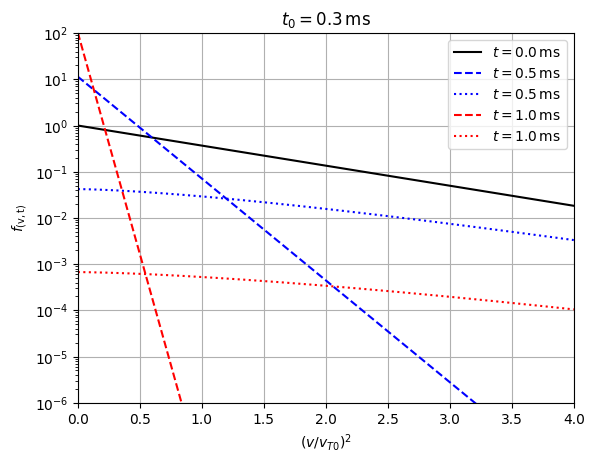

In [30]:
T0 = 3.1e3        # eV
Tf = 0.01*T0      # eV
t0 = 3e-4           # s
n0 = 2.8e19           # m^-3

tau = 0
vT0 = getvT0(T0)
print("vT0:", vT0)
x = np.linspace(0, 4, 8000)      # x = (v / vT0)^2
v = np.sqrt(x)*vT0

fm = getfm(v, n0, vT0)
norm_fac = max(fm)

plt.plot(x, fm/norm_fac, "k", label=rf"$t = {tau*1e3:.1f}\,\mathrm{{ms}}$")
plt.xlabel(r"$(v / v_{T0})^2$")
plt.yscale("log")
plt.ylim((1e-6, 1e2))
plt.xlim((0,4))
plt.ylabel(r"$f_{\mathrm{(v,t)}}$")
plt.title(r"$t_0 = 0.3\,\mathrm{ms}$")

plt.grid(True)

t = 5e-4
T = temperature(t, T0, Tf, t0)
vT = getvT0(T)
fm = getfm(v, n0, vT)
plt.plot(x, fm/norm_fac, "b--", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")

nu0 = getnu0(n0, T0)
tau = getTau(nu0, t, t0)
f = getf(v, n0, vT0, tau)
plt.plot(x, f/norm_fac, "b:", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")

t = 1e-3
T = temperature(t, T0, Tf, t0)
vT = getvT0(T)
fm = getfm(v, n0, vT)
plt.plot(x, fm/norm_fac, "r--", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")

nu0 = getnu0(n0, T0)
tau = getTau(nu0, t, t0)
f = getf(v, n0, vT0, tau)
plt.plot(x, f/norm_fac, "r:", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")

plt.legend()


vT0: 33022241.068624627


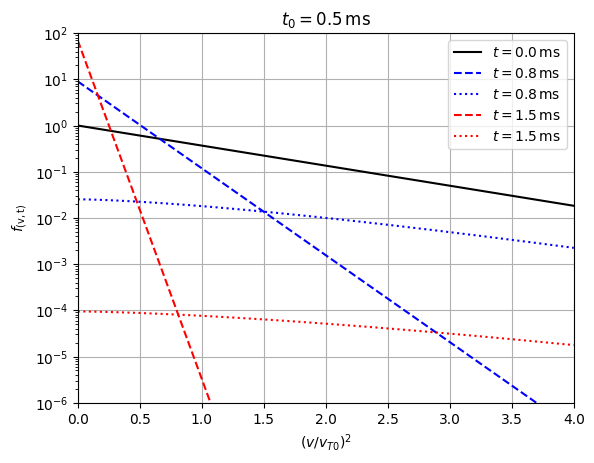

In [33]:
T0 = 3.1e3        # eV
Tf = 0.01*T0      # eV
t0 = 5e-4           # s
n0 = 2.8e19           # m^-3

tau = 0
vT0 = getvT0(T0)
print("vT0:", vT0)
x = np.linspace(0, 4, 8000)      # x = (v / vT0)^2
v = np.sqrt(x)*vT0

fm = getfm(v, n0, vT0)
norm_fac = max(fm)

plt.plot(x, fm/norm_fac, "k", label=rf"$t = {tau*1e3:.1f}\,\mathrm{{ms}}$")
plt.xlabel(r"$(v / v_{T0})^2$")
plt.yscale("log")
plt.ylim((1e-6, 1e2))
plt.xlim((0,4))
plt.ylabel(r"$f_{\mathrm{(v,t)}}$")
plt.title(r"$t_0 = 0.5\,\mathrm{ms}$")

plt.grid(True)

t = 7.5e-4
T = temperature(t, T0, Tf, t0)
vT = getvT0(T)
fm = getfm(v, n0, vT)
plt.plot(x, fm/norm_fac, "b--", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")

nu0 = getnu0(n0, T0)
tau = getTau(nu0, t, t0)
f = getf(v, n0, vT0, tau)
plt.plot(x, f/norm_fac, "b:", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")

t = 1.5e-3
T = temperature(t, T0, Tf, t0)
vT = getvT0(T)
fm = getfm(v, n0, vT)
plt.plot(x, fm/norm_fac, "r--", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")

nu0 = getnu0(n0, T0)
tau = getTau(nu0, t, t0)
f = getf(v, n0, vT0, tau)
plt.plot(x, f/norm_fac, "r:", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")

plt.legend()


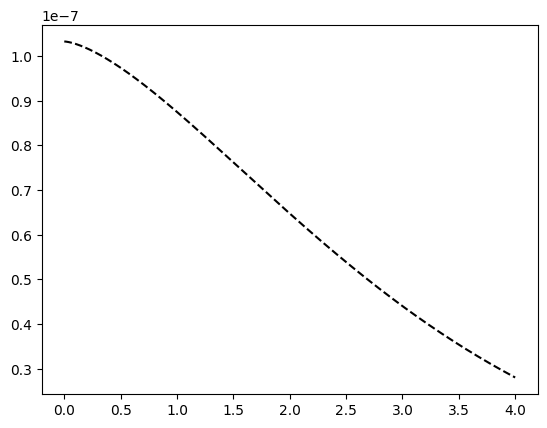

In [22]:
plt.plot(x, f/norm_fac, "k--", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")

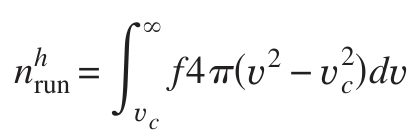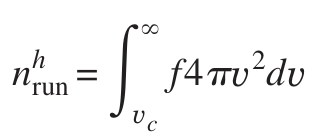

In [ ]:
'''
def getEd(nu0, T):
    
    nu0: collision rate (s^-1)
    T: temperature (eV)
    
    nu_rel = getDreicerField()
    return m**2 * c**3 * nu0/(e*T)
'''



def getv_c(T0, T, n0, n, ED0, E0):
    '''
    T0: temperature at t=0 (eV)
    T: temperature (eV)
    n0: density (m^-3) at t=0
    n: density (m^-3)
    ED0: Dreicer field at t=0 (V/m or N/C)
    E0: Electric field at t=0 (V/m or N/C)
    '''

    t1 = np.sqrt((T0*e*ED0)/(m*E0))
   # print('t1:', t1)
    t2 = (T/T0)**0.75 * (n/n0)**0.5
   # print('t2:', t2)
    return t1 * t2
    

In [ ]:
from scipy.integrate import trapezoid


def getnrun(f, v, vc):
    sol = cumulative_trapezoid(f*4*np.pi*v**2, x=v)
    #print(sol)
    vc_index = np.searchsorted(v, vc)
    return sol[-1] - sol[vc_index]
'''
def getnrun(f, v, vc):
    sol = cumulative_trapezoid(f * 4*np.pi*v**2, x=v, initial=0)
    return np.interp(vc, v, sol, right=sol[-1], left=0.0)
'''

def getnrun2(f, v, vc):
    sol = cumulative_trapezoid(f*4*np.pi*(v**2 - vc**2), x=v, initial=None)
    #print(sol)
    vc_index = np.searchsorted(v, vc)
    return sol[-1] - sol[vc_index]


In [121]:
def integral_solution(t_array, v, n0, T0, Tf, t0, E0, ED0):
    """
    Returns n_run(t)/n(t) evaluated using the integral solution
    """

    vT0 = getvT0(T0)
    nu0 = getnu0(n0, T0)

    nrun_over_n = []

    for t in t_array:
        T = temperature(t, T0, Tf, t0)

        # I think the density is estimated to be constant but double check
        n = n0
        tau = getTau(nu0, t, 0.0)
        f = getf(v, n0, vT0, tau)
        #print(f)

        vc = getv_c(T0, T, n0, n, ED0, E0)
        print("vc:", vc)

        nrun = getnrun2(f, v, vc)

        # normalize
        nrun_over_n.append(nrun / n)

    return np.array(nrun_over_n)


ED0: 3.5302142172605437
vc (m/s): 13626670.692633113
0.001771154663179268


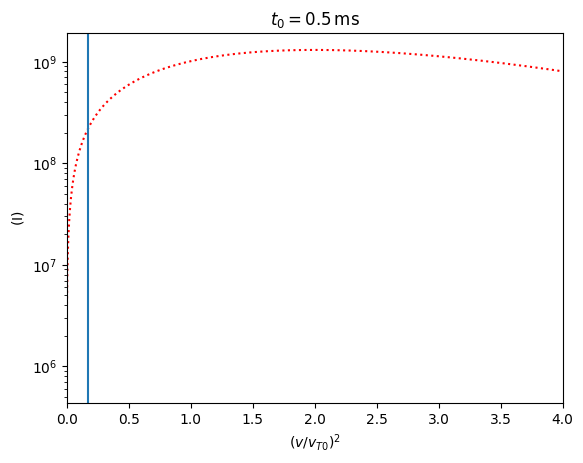

In [ ]:
T0 = 3.1e3        # eV
Tf = 0.01*T0      # eV
t0 = 3e-4           # s
n0 = 2.8e19           # m^-3
E0 = 1
ED0 = getDreicerField(n0, 15, T0)
print("ED0:", ED0)

vT0 = getvT0(T0)
x = np.linspace(0, 4, 8000)      # x = (v / vT0)^2
v = np.sqrt(x)*vT0



t = 1e-3


T = temperature(t, T0, Tf, t0)

nu0 = getnu0(n0, T0)
tau = getTau(nu0, t, t0)
f = getf(v, n0, vT0, tau)
I = 4*np.pi*v**2*f
vc = getv_c(T0, T, n0, n0, ED0, E0)
print("vc (m/s):", vc)


plt.plot(x, I, "r:", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")
plt.xlabel(r"$(v / v_{T0})^2$")
plt.yscale("log")
#plt.ylim((1e-6, 1e2))
plt.axvline(x=(vc/vT0)**2)
plt.xlim((0,4))
plt.ylabel(r"${\mathrm{(I)}}$")
plt.title(r"$t_0 = 0.5\,\mathrm{ms}$")

from scipy.integrate import trapezoid
i = np.argwhere(v>vc)
#print(i)
n_re = trapezoid(I[i].flatten(), x=v[i].flatten()) 
print(n_re/n0)



### Ignore this for now 

4.232080613604756e-16
[       0.           738445.91230019  1044320.2242539  ...
 66036225.02874199 66040353.71204521 66044482.13724925]
vc: 0.48036185305306783
vc: 0.4799161154429307
vc: 0.47947079701407586
vc: 0.4790258973740205
vc: 0.47858141613065025
vc: 0.478137352892218
vc: 0.4776937072673439
vc: 0.4772504788650152
vc: 0.4768076672945858
vc: 0.47636527216577573
vc: 0.4759232930886708
vc: 0.4754817296737226
vc: 0.4750405815317479
vc: 0.4745998482739282
vc: 0.4741595295118096
vc: 0.47371962485730257
vc: 0.47328013392268126
vc: 0.4728410563205832
vc: 0.4724023916640094
vc: 0.4719641395663234
vc: 0.47152629964125137
vc: 0.4710888715028818
vc: 0.4706518547656646
vc: 0.4702152490444115
vc: 0.4697790539542951
vc: 0.46934326911084906
vc: 0.4689078941299672
vc: 0.46847292862790374
vc: 0.4680383722212724
vc: 0.46760422452704653
vc: 0.4671704851625586
vc: 0.4667371537454998
vc: 0.46630422989391956
vc: 0.4658717132262257
vc: 0.4654396033611838
vc: 0.46500789991791647
vc: 0.4645766025159039
v

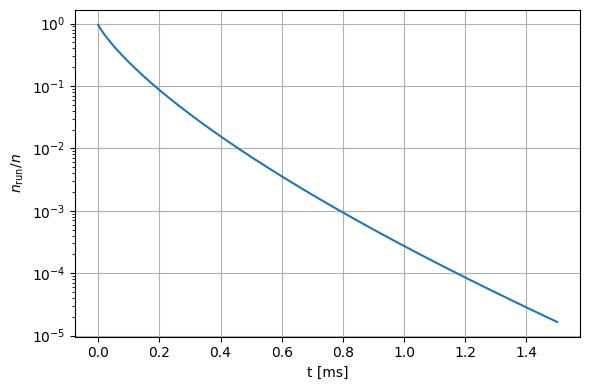

In [128]:
T0 = 3.1e3        # eV
Tf = 0.01*T0      # eV
t0 = 3e-4           # s
n0 = 2.8e19           # m^-3
E0 = 1
ED0 = getEd(nu0, T0)
print(ED0)

vT0 = getvT0(T0)
x = np.linspace(0, 4, 8000)      # x = (v / vT0)^2
v = np.sqrt(x)*vT0
print(v)

t = np.linspace(0, 1.5e-3, 4000)


nrun_over_n = integral_solution(
    t, v, n0, T0, Tf, t0, E0, ED0
)

# Plot
plt.figure(figsize=(6,4))
plt.plot((t*1e3), nrun_over_n)
plt.xlabel('t [ms]')
plt.ylabel(r'$n_{\rm run}/n$')
plt.yscale('log')
plt.grid()
plt.tight_layout()
plt.show()

In [53]:
T0 = 3.1e3        # eV
Tf = 0.01*T0      # eV
t0 = 3e-4           # s
n0 = 2.8e19           # m^-3
E0 = 1

vT0 = getvT0(T0)
x = np.linspace(0, 4, 8000)      # x = (v / vT0)^2
v = np.sqrt(x)*vT0

t = np.linspace(0, 1.5e-3, 4000)
nu0 = getnu0(n0, T0)
ED0 = getEd(nu0, T0)

nrun = []
for ti in t:
    T = temperature(ti, T0, Tf, t0)
    tau = getTau(nu0, ti, t0)
    f = getf(v, n0, vT0, tau)
    ED0 = getEd(nu0, T)
    vc = getv_c(T0, T, n0, n, ED0, E0)
    nrun_1 = getnrun(f, v, )
    nrun.append(f)


print(f)

NameError: name 'n' is not defined